# 03 - Regime Detection (HMM)

Classifies the Kalman spread into regimes (calm/mean-reverting vs volatile/trending) with a Gaussian HMM, and produces a causal, walk-forward regime probability for notebook 04 to gate trading on. This is the piece that connects most directly to the dissertation's Markov-model work, and the one worth understanding the most deeply.

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hmmlearn.hmm import GaussianHMM

warnings.filterwarnings("ignore", message="Model is not converging")

DATA_DIR = "../data"

with open(f"{DATA_DIR}/kalman_config.json") as f:
    kconfig = json.load(f)

BURN_IN = kconfig["burn_in"]
fx = pd.read_parquet(f"{DATA_DIR}/kalman_fx.parquet").iloc[BURN_IN:]
comm = pd.read_parquet(f"{DATA_DIR}/kalman_comm.parquet").iloc[BURN_IN:]

print("FX:", fx.index.min().date(), "->", fx.index.max().date(), fx.shape)
print("Commodities:", comm.index.min().date(), "->", comm.index.max().date(), comm.shape)

FX: 2014-03-26 -> 2024-08-14 (2708, 6)
Commodities: 2007-10-23 -> 2024-08-14 (4176, 6)


## Features

Two, both from the Kalman spread: the daily change, and its 10-day rolling volatility (separates calm/range-bound periods from volatile/trending ones). Both only look backward, so nothing here introduces look-ahead.

In [2]:
def build_features(spread, vol_window=10):
    d_spread = spread.diff()
    vol = d_spread.rolling(vol_window).std()
    return pd.DataFrame({"d_spread": d_spread, "vol": vol}).dropna()

fx_feats = build_features(fx["kalman_spread"])
comm_feats = build_features(comm["kalman_spread"])
print(fx_feats.shape, comm_feats.shape)

(2698, 2) (4166, 2)


## How many states?

BIC will always improve with more states, which alone isn't a good reason to use them. Computed once on the full training sample as an offline architecture decision, fixed before any walk-forward fitting starts - so it doesn't reintroduce look-ahead into the live signal.

In [3]:
def standardize(X, mu=None, sd=None):
    if mu is None:
        mu, sd = X.mean(axis=0), X.std(axis=0)
    return (X - mu) / sd, mu, sd

def bic_for_k(X, k, seed=42):
    Xn, _, _ = standardize(X)
    m = GaussianHMM(n_components=k, covariance_type="diag", n_iter=200, tol=1e-4, random_state=seed)
    m.fit(Xn)
    ll = m.score(Xn)
    n_features = X.shape[1]
    n_params = k * (k - 1) + (k - 1) + 2 * k * n_features
    bic = -2 * ll + n_params * np.log(len(Xn))
    return ll, bic

bic_table = []
for k in [2, 3, 4]:
    ll, bic = bic_for_k(fx_feats.values, k)
    bic_table.append({"n_states": k, "loglik": ll, "BIC": bic})
bic_df = pd.DataFrame(bic_table).set_index("n_states")
print(bic_df)

with open(f"{DATA_DIR}/hmm_state_count_selection.md", "w") as f:
    f.write("# HMM state count\n\n" + bic_df.to_markdown() + "\n\n"
            "BIC keeps improving as states are added, which is typical for HMMs - more flexibility "
            "always fits the training data better. Going with 2 states anyway: it keeps the trading "
            "gate simple (trade / don't trade) and each regime interpretable as calm vs volatile, "
            "rather than needing a post-hoc story for 3-4 abstract states. Interpretability over "
            "fit, deliberately.\n")

print("\nUsing 2 states - see hmm_state_count_selection.md for the reasoning.")

               loglik           BIC
n_states                           
2        -6075.493901  12237.890729
3        -6020.787118  12199.579556
4        -4810.362201   9865.632649

Using 2 states - see hmm_state_count_selection.md for the reasoning.


## Walk-forward fitting, causal filtering

Two look-ahead traps here. First, fitting the HMM once on the full sample has, by definition, seen the future relative to any historical date - so it's refit periodically (every ~quarter) on an expanding window of past data only. Second, hmmlearn's default `.predict_proba()` runs forward-backward (smoothing), which uses future observations to improve estimates of earlier ones - fine offline, wrong for a trading signal. Implemented by hand below instead: the plain forward algorithm, giving $P(z_t \mid y_1,\dots,y_t)$ from the past only.

State labels also aren't guaranteed to mean the same thing between two fits, so after each refit the "calm" state is re-identified as whichever has the lower volatility-feature mean.

In [4]:
def manual_forward_filter(model, X):
    """Causal filtered state probabilities P(z_t | y_1..y_t). No backward pass."""
    log_frameprob = model._compute_log_likelihood(X)
    n_samples, n_components = log_frameprob.shape
    with np.errstate(divide="ignore"):  # log(0) -> -inf is correct for an impossible transition
        log_startprob = np.log(model.startprob_)
        log_transmat = np.log(model.transmat_)

    fwd = np.zeros((n_samples, n_components))
    fwd[0] = log_startprob + log_frameprob[0]
    fwd[0] -= np.logaddexp.reduce(fwd[0])
    for t in range(1, n_samples):
        for j in range(n_components):
            fwd[t, j] = np.logaddexp.reduce(fwd[t - 1] + log_transmat[:, j]) + log_frameprob[t, j]
        fwd[t] -= np.logaddexp.reduce(fwd[t])
    return np.exp(fwd)


def walk_forward_hmm(feats, n_states=2, refit_every=63, min_train=252, seed=42):
    X = feats.values
    n = len(X)

    calm_prob = np.full(n, np.nan)
    transmats = []

    for start in range(min_train, n, refit_every):
        train_X = X[:start]
        train_Xn, mu, sd = standardize(train_X)

        model = GaussianHMM(n_components=n_states, covariance_type="diag", n_iter=200, tol=1e-4, random_state=seed)
        model.fit(train_Xn)
        transmats.append(model.transmat_.copy())

        calm_state = np.argmin(model.means_[:, 1])  # lowest standardized 'vol' feature -> calm

        end = min(start + refit_every, n)
        block_Xn = (X[start:end] - mu) / sd  # standardize new block using train-only mu/sd
        probs = manual_forward_filter(model, block_Xn)
        calm_prob[start:end] = probs[:, calm_state]

    return pd.Series(calm_prob, index=feats.index, name="calm_prob"), transmats

REFIT_EVERY, MIN_TRAIN = 63, 252

fx_calm_prob, fx_transmats = walk_forward_hmm(fx_feats, refit_every=REFIT_EVERY, min_train=MIN_TRAIN)
comm_calm_prob, comm_transmats = walk_forward_hmm(comm_feats, refit_every=REFIT_EVERY, min_train=MIN_TRAIN)

print(f"FX: {fx_calm_prob.notna().mean()*100:.1f}% coverage after {MIN_TRAIN}-day initial training window")
print(f"Commodities: {comm_calm_prob.notna().mean()*100:.1f}% coverage after {MIN_TRAIN}-day initial training window")

FX: 90.7% coverage after 252-day initial training window
Commodities: 94.0% coverage after 252-day initial training window


## Are these regimes real?

Before trusting them: check they're persistent rather than the model flipping states every day. The average diagonal of the transition matrix across all refits tells us this - high self-transition probability means a regime tends to stick once entered.

In [5]:
def avg_diag(transmats):
    diags = np.array([np.diag(t) for t in transmats])
    return diags.mean(axis=0), diags.std(axis=0)

fx_diag_mean, fx_diag_std = avg_diag(fx_transmats)
comm_diag_mean, comm_diag_std = avg_diag(comm_transmats)

print("AUD/NZD avg self-transition probability per state:", np.round(fx_diag_mean, 3), "+/-", np.round(fx_diag_std, 3))
print("WTI/BRENT avg self-transition probability per state:", np.round(comm_diag_mean, 3), "+/-", np.round(comm_diag_std, 3))
print("\nImplied average regime duration (days) = 1 / (1 - self-transition prob):")
print("AUD/NZD:", np.round(1 / (1 - fx_diag_mean), 1))
print("WTI/BRENT:", np.round(1 / (1 - comm_diag_mean), 1))

AUD/NZD avg self-transition probability per state: [0.854 0.838] +/- [0.257 0.29 ]
WTI/BRENT avg self-transition probability per state: [0.967 0.944] +/- [0.025 0.039]

Implied average regime duration (days) = 1 / (1 - self-transition prob):
AUD/NZD: [6.8 6.2]
WTI/BRENT: [30.4 17.8]


## Regimes against the spread

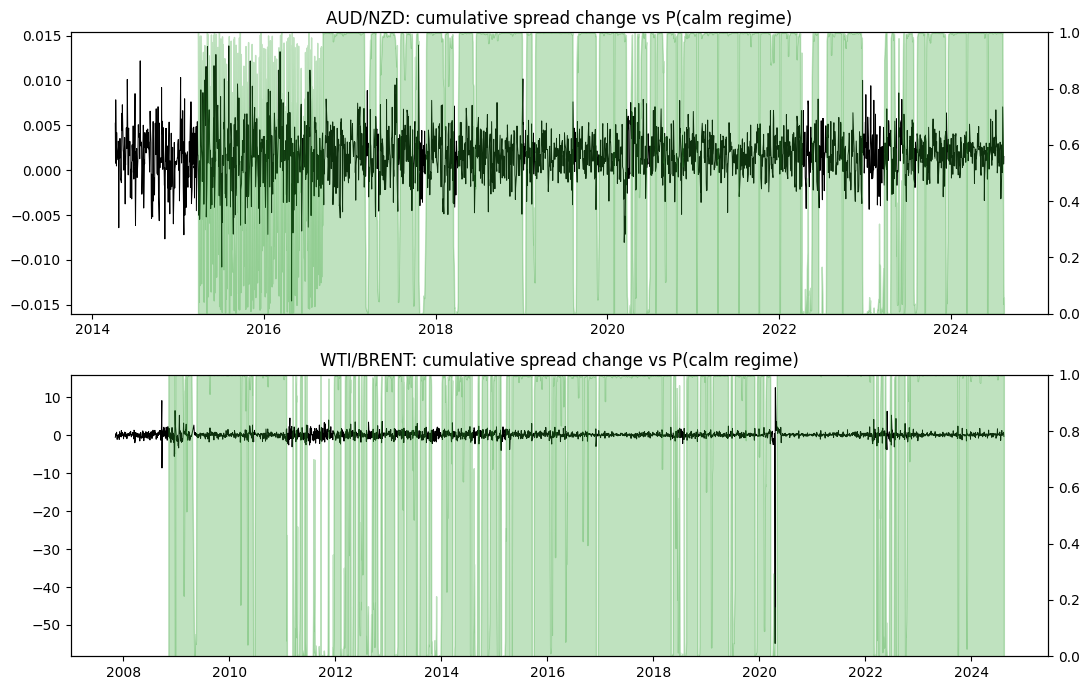

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=False)

ax = axes[0]
ax.plot(fx.loc[fx_feats.index].index, fx_feats["d_spread"].cumsum(), color="black", linewidth=0.7, label="cumulative spread change")
ax2 = ax.twinx()
ax2.fill_between(fx_calm_prob.index, 0, fx_calm_prob, color="#2ca02c", alpha=0.3, label="P(calm regime)")
ax2.set_ylim(0, 1)
ax.set_title("AUD/NZD: cumulative spread change vs P(calm regime)")

ax = axes[1]
ax.plot(comm.loc[comm_feats.index].index, comm_feats["d_spread"].cumsum(), color="black", linewidth=0.7, label="cumulative spread change")
ax2 = ax.twinx()
ax2.fill_between(comm_calm_prob.index, 0, comm_calm_prob, color="#2ca02c", alpha=0.3, label="P(calm regime)")
ax2.set_ylim(0, 1)
ax.set_title("WTI/BRENT: cumulative spread change vs P(calm regime)")

plt.tight_layout()
plt.savefig(f"{DATA_DIR}/03_regime_overlay.png", dpi=120)
plt.show()

This is the piece most exposed to "are these real regimes or overfit noise" - the persistence check above is the first check, and notebook 06's ablation (backtest with vs without the filter) is the second and more decisive one.

## Save

In [7]:
fx_out = fx_calm_prob.to_frame()
fx_out["regime_label"] = np.where(fx_out["calm_prob"] > 0.5, "calm", "volatile")
fx_out.to_parquet(f"{DATA_DIR}/regime_fx.parquet")

comm_out = comm_calm_prob.to_frame()
comm_out["regime_label"] = np.where(comm_out["calm_prob"] > 0.5, "calm", "volatile")
comm_out.to_parquet(f"{DATA_DIR}/regime_comm.parquet")

regime_config = {"refit_every": REFIT_EVERY, "min_train": MIN_TRAIN, "n_states": 2, "vol_window": 10}
with open(f"{DATA_DIR}/regime_config.json", "w") as f:
    json.dump(regime_config, f, indent=2)

print("Saved regime_fx.parquet, regime_comm.parquet, regime_config.json to", DATA_DIR)
print(f"NOTE: first {MIN_TRAIN} rows of each are NaN (no regime estimate before the initial training window) "
      "- notebook 04/05 must handle this, in addition to the notebook 02 burn-in already dropped here.")
print("\nRegime label distribution:")
print("AUD/NZD:", fx_out["regime_label"].value_counts(normalize=True).round(3).to_dict())
print("WTI/BRENT:", comm_out["regime_label"].value_counts(normalize=True).round(3).to_dict())

Saved regime_fx.parquet, regime_comm.parquet, regime_config.json to ../data
NOTE: first 252 rows of each are NaN (no regime estimate before the initial training window) - notebook 04/05 must handle this, in addition to the notebook 02 burn-in already dropped here.

Regime label distribution:
AUD/NZD: {'calm': 0.716, 'volatile': 0.284}
WTI/BRENT: {'calm': 0.75, 'volatile': 0.25}


Notebook 04 gates entries on `calm_prob > 0.5`, and also needs to treat the first `min_train` rows as warm-up with no usable signal.